# Anomaly Detection Using Isolation Forest and K-Means Clustering for Risk Assessment
This notebook explores corporate income tax payment records, performs data quality checks, identifies records that differ from the wider population using Isolation Forest anomaly detection, and groups observations with similar anomaly characteristics using K-Means clustering.
The notebook also examines the distribution of anomaly scores through exploratory analysis, evaluates the separation of anomaly groups, and develops a risk based category for prioritising taxpayers for further investigation.

The resulting outputs are intended to support risk assessment and investigative review, rather than provide direct evidence of non compliance or fraud.

## 1. Setup
Install packages from `requirements.txt`. 

In [62]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## 2. Load the source data

The data was downloaded from https://statbase.org/data/gha-tax-revenue/, you may need to create an account and pay for subscription to be able to download the full data. I have provided a sample of the data for this project.
Expected columns are `TIN`, `Year`, and the twelve monthly payment columns.

In [36]:
# Data path
data_path = Path("data/Tax_data.csv")

#Loading the data
def load_tax_data(path):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"could not find {path.resolve()}"
        )

    return pd.read_csv(path)

# View the data
data_tax = load_tax_data(data_path)
display(data_tax.head())

,TIN,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,C2222479742,2018,0.0,0.0,0.0,0.0,0.0,3125.0000,0.0,0.0000,0.00000,3125.0,0.0,0.0000
1,C2222479742,2019,0.0,0.0,0.0,0.0,0.0,69358.0000,69358.0,69358.0000,64395.19141,0.0,0.0,0.0000
2,C2222479742,2021,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0000,0.00000,0.0,2500.0,7500.0000
3,C2222672947,2018,0.0,0.0,20000.0,1190615.0,0.0,100000.0000,0.0,0.0000,70000.00000,0.0,0.0,0.0000
4,C2222747189,2020,0.0,0.0,0.0,0.0,0.0,153052.9219,0.0,132922.3125,0.00000,0.0,0.0,153052.9219


## 3. Reusable data cleaning function

The function `clean_tax_data()` accepts a DataFrame and returns a cleaned copy, and a quality report. I have normalised column names, kept TIN as text, converted year, and payment fields to numeric. It reports missing values, duplicates, invalid numeric values, negative payments, and special characters.

If special characters, and negative values will be flagged for a review.

In [43]:
#I am putting the data cleaning in a simple function clean_tax_data()
def clean_tax_data(
    data: pd.DataFrame,
    *,
    fill_missing_payments: bool = False,
    required_columns: tuple[str, ...] = ("TIN", "Year", *MONTHS),
) -> tuple[pd.DataFrame, dict]:

    #Cleaned copy and a dictionary of data quality summaries.
    if not isinstance(data, pd.DataFrame):
        raise TypeError("data must be a pandas DataFrame.")
    if data.empty:
        raise ValueError("The input DataFrame is empty.")

    cleaned = data.copy()
    cleaned.columns = cleaned.columns.astype(str).str.strip()

    duplicates = cleaned.columns[cleaned.columns.duplicated()].tolist()
    if duplicates:
        raise ValueError(f"Duplicate column names after trimming: {duplicates}")

    missing_required = [c for c in required_columns if c not in cleaned.columns]
    if missing_required:
        raise ValueError(f"Required columns are missing: {missing_required}")

    rows_before = len(cleaned)
    duplicate_rows = int(cleaned.duplicated().sum())

    # I will keep TIN as text
    cleaned["TIN"] = cleaned["TIN"].astype("string").str.strip().replace("", pd.NA)

    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        if column != "TIN":
            cleaned[column] = cleaned[column].astype("string").str.strip()

    invalid_numeric = {}
    for column in ["Year", *MONTHS]:
        original_non_missing = cleaned[column].notna()
        converted = pd.to_numeric(cleaned[column], errors="coerce")
        invalid_numeric[column] = int((original_non_missing & converted.isna()).sum())
        cleaned[column] = converted

    missing_before_fill = cleaned.isna().sum().astype(int)
    if fill_missing_payments:
        cleaned[MONTHS] = cleaned[MONTHS].fillna(0)

    negative_mask = cleaned[MONTHS].lt(0).fillna(False)
    negative_payment_rows = cleaned.loc[
        negative_mask.any(axis=1), ["TIN", "Year", *MONTHS]
    ].copy()

    special_cells = []
    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        mask = cleaned[column].astype("string").str.contains(
            r"[^a-zA-Z0-9\s]", regex=True, na=False
        )
        for idx in cleaned.index[mask]:
            special_cells.append({
                "row_index": idx, "column": column, "value": cleaned.at[idx, column]
            })

    report = {
        "rows_before": rows_before,
        "rows_after": len(cleaned),
        "duplicate_rows": duplicate_rows,
        "missing_values_before_optional_fill": missing_before_fill,
        "invalid_numeric_values": pd.Series(invalid_numeric, name="invalid_count"),
        "negative_payment_rows": negative_payment_rows,
        "special_character_cells": pd.DataFrame(
            special_cells, columns=["row_index", "column", "value"]
        ),
    }
    return cleaned, report

### Run the cleaning function

Loading dataset and parsing it through the  clean_tax_data function to clean the data.

In [44]:
#Now I will parse the data 
data_tax = load_tax_data(data_path)
cleaned_tax_data, quality_report = clean_tax_data(
     data_tax,
     fill_missing_payments=False,
 )

display(cleaned_tax_data.head())
print(f"Rows before cleaning: {quality_report['rows_before']:,}")
print(f"Rows after cleaning:  {quality_report['rows_after']:,}")
print(f"Exact duplicate rows: {quality_report['duplicate_rows']:,}")
display(quality_report["missing_values_before_optional_fill"].to_frame("missing_count"))
display(quality_report["invalid_numeric_values"].to_frame())
display(quality_report["negative_payment_rows"].head(20))
display(quality_report["special_character_cells"].head(20))

,TIN,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,C2222479742,2018,0.0,0.0,0.0,0.0,0.0,3125.0000,0.0,0.0000,0.00000,3125.0,0.0,0.0000
1,C2222479742,2019,0.0,0.0,0.0,0.0,0.0,69358.0000,69358.0,69358.0000,64395.19141,0.0,0.0,0.0000
2,C2222479742,2021,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0000,0.00000,0.0,2500.0,7500.0000
3,C2222672947,2018,0.0,0.0,20000.0,1190615.0,0.0,100000.0000,0.0,0.0000,70000.00000,0.0,0.0,0.0000
4,C2222747189,2020,0.0,0.0,0.0,0.0,0.0,153052.9219,0.0,132922.3125,0.00000,0.0,0.0,153052.9219


Rows before cleaning: 655
Rows after cleaning:  655
Exact duplicate rows: 2


,missing_count
TIN,0
Year,0
Jan,0
Feb,0
Mar,0
Apr,0
May,0
Jun,0
Jul,0
Aug,0


,invalid_count
Year,0
Jan,0
Feb,0
Mar,0
Apr,0
May,0
Jun,0
Jul,0
Aug,0
Sep,0


,TIN,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec


,row_index,column,value


## 5. Taxpayers with no monthly records

I want to know whether there are fields where all twelve monthly payment fields is zero.
There were no tax payment but their details is in the dataset. There were none.

I did not remove where payment fields are zero because they may be accurate, the data does not provide
any context (no metadata available to support that case).

In [48]:
def find_zero_payment_records(data: pd.DataFrame) -> pd.DataFrame:
    
    #Returning records with taxpayment across all the 12 month period
    missing_months = data[MONTHS].isna().any(axis=1)
    all_months_zero = data[MONTHS].eq(0).all(axis=1)
    return data.loc[~missing_months & all_months_zero].copy()

zero_payment_records = find_zero_payment_records(cleaned_tax_data)
print(f"Records with all 12 monthly payments recorded as zero: {len(zero_payment_records):,}")
display(zero_payment_records.head(20))

Records with all 12 monthly payments recorded as zero: 0


,TIN,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec


## 6. Anomaly detection with Isolation Forest

Now that we know our data is in its best form. Lets carry out the anomaly detection using Isolation Forest.
For a brief info: Isolation forest identifies records that are relatively unusual compared with the records supplied to the model. 
In this with the tax data, it will use `Year` and monthly payments. 

Why not TIN? the TIN is an identifier, and identifiers will not drive any statistical result.

- `Contamination`: The contamination parameter tells the model the percentage of the observations to be anomalies.

In [49]:
def detect_anomalies(
    data: pd.DataFrame,
    *,
    contamination: float = 0.20,
    random_state: int = RANDOM_STATE,
) -> tuple[pd.DataFrame, IsolationForest]:
    
    #Fitting Isolation forest model and appendding anomaly score
    features = ["Year", *MONTHS]
    missing_columns = [c for c in features if c not in data.columns]
    if missing_columns:
        raise ValueError(f"Missing anomaly features: {missing_columns}")

    X = data[features].apply(pd.to_numeric, errors="coerce")
    valid = X.notna().all(axis=1)
    if valid.sum() < 2:
        raise ValueError("At least two complete rows are required for anomaly detection.")

    model = IsolationForest(
        contamination=contamination, random_state=random_state, n_estimators=200
    )
    result = data.copy()
    result["anomaly_scores"] = np.nan
    result["anomaly"] = pd.Series(pd.NA, index=result.index, dtype="Int64")

    model.fit(X.loc[valid])
    result.loc[valid, "anomaly_scores"] = model.decision_function(X.loc[valid])
    result.loc[valid, "anomaly"] = model.predict(X.loc[valid])
    return result, model

#Parsing the cleaned tax_data to detect_anomalies function
anomaly_data, isolation_forest_model = detect_anomalies(cleaned_tax_data)
display(anomaly_data["anomaly"].value_counts(dropna=False).rename(
     index={1: "Typical pattern", -1: "Flagged as unusual"}
 ))

C:\Users\Kofi Siriboe\anaconda3\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
C:\Users\Kofi Siriboe\AppData\Local\Temp\ipykernel_44052\4203838329.py:27: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  result.loc[valid, "anomaly"] = model.predict(X.loc[valid])


Typical pattern       524
Flagged as unusual    131
Name: anomaly, dtype: int64

### Interpreting the anomaly scores below
After I run the tax_data through the detect_anomalies, the model flagged 131 records.
This is how to interpret the scores acording to isolation forest.
- `Anomaly = -1`: means the model flags the record as unusual relative to the rest of the taxpayers.
- `Anomaly = 1`: means the model does not flag the record as unusual.
- `Anomaly_scores`: tells you how different an observation is from the rest of the taxpayers. 
A lower anomaly socre generally indicates more unusual taxpayers; higher values indicates normal taxpayers.

In [50]:
# Reviewing the most unusual records first in table form.
#This is helpful to review individual records.
anomaly_review = anomaly_data.loc[anomaly_data["anomaly"].eq(-1)].sort_values(
     "anomaly_scores", ascending=True
 )
display(anomaly_review[["TIN", "Year", "anomaly_scores", "anomaly", *MONTHS]].head(25))

,TIN,Year,anomaly_scores,anomaly,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
386,C2223268271,2019,-0.436435,-1,0.000000e+00,0.0,7.484691e+07,9.681869e+06,5.130736e+06,8.559186e+07,0.000,0.000,9.401351e+07,0.000000e+00,0.000000e+00,119971256.0
387,C2223268271,2020,-0.421622,-1,0.000000e+00,0.0,2.966732e+07,0.000000e+00,0.000000e+00,1.006252e+08,0.000,0.000,7.640196e+07,0.000000e+00,5.703172e+07,96051536.0
595,C222771978X,2020,-0.398067,-1,0.000000e+00,0.0,3.050851e+07,0.000000e+00,0.000000e+00,3.945838e+07,0.000,0.000,3.945838e+07,0.000000e+00,6.184269e+07,160832560.0
245,C2223137227,2020,-0.367937,-1,0.000000e+00,0.0,0.000000e+00,0.000000e+00,1.147292e+07,4.993390e+07,0.000,0.000,7.312504e+07,0.000000e+00,0.000000e+00,76934016.0
121,C2222788217,2018,-0.305597,-1,0.000000e+00,0.0,2.574773e+07,6.850298e+06,0.000000e+00,2.619343e+07,0.000,0.000,2.891796e+07,0.000000e+00,0.000000e+00,32424782.0
246,C2223137227,2021,-0.298385,-1,0.000000e+00,0.0,0.000000e+00,3.063971e+07,0.000000e+00,2.922929e+07,0.000,0.000,0.000000e+00,0.000000e+00,1.939065e+07,58171960.0
385,C2223268271,2018,-0.292312,-1,0.000000e+00,0.0,2.514783e+07,0.000000e+00,0.000000e+00,2.579317e+07,0.000,0.000,2.575908e+07,0.000000e+00,0.000000e+00,66413960.0
371,C2223277673,2020,-0.292155,-1,0.000000e+00,0.0,6.890866e+06,0.000000e+00,0.000000e+00,3.095106e+07,0.000,0.000,4.720404e+07,1.628196e+06,0.000000e+00,13568206.0
390,C2223278263,2021,-0.270227,-1,1.088187e+08,0.0,0.000000e+00,1.094362e+08,0.000000e+00,0.000000e+00,0.000,0.000,0.000000e+00,0.000000e+00,0.000000e+00,0.0
596,C222771978X,2021,-0.269569,-1,0.000000e+00,0.0,0.000000e+00,2.997372e+07,0.000000e+00,6.274866e+05,0.000,0.000,0.000000e+00,0.000000e+00,4.312246e+07,129367368.0


### Visualise anomaly scores
Now I will visualise the anomaly records to see how they are clustered.
The output of the histogram is left skewed, with majority of the anomaly records around a score of 0.02 to 0.04.

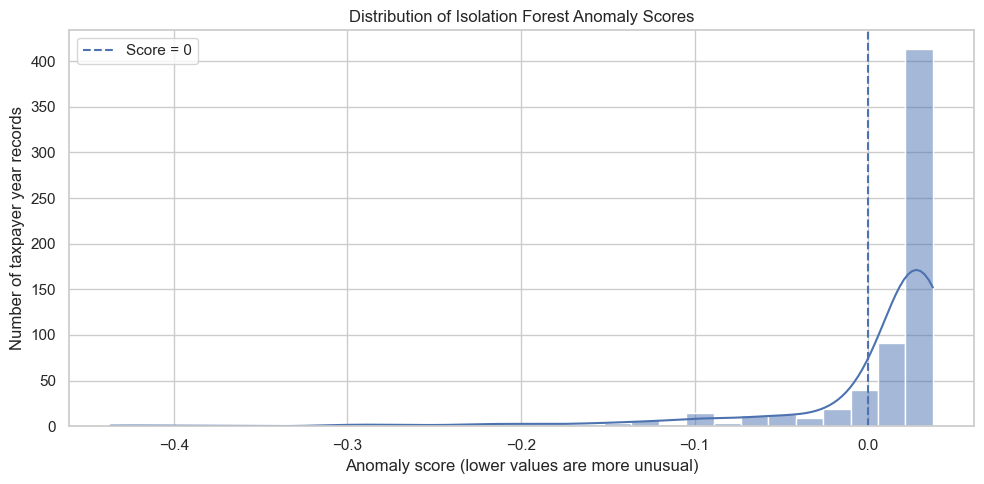

In [53]:
valid_scores = anomaly_data["anomaly_scores"].dropna()
plt.figure(figsize=(10, 5))
sns.histplot(valid_scores, bins=30, kde=True)
plt.axvline(0, linestyle="--", label="Score = 0")
plt.title("Distribution of Isolation Forest Anomaly Scores")
plt.xlabel("Anomaly score (lower values are more unusual)")
plt.ylabel("Number of taxpayer year records")
plt.legend()
plt.tight_layout()
plt.show()

### How does this reflect in terms of the percentage of anomalies in the data?
The most anomalous 1% of taxpayers have scores below -0.292.
The most anomalous 5% have scores below -0.126.
The most anomalous 10% have scores below -0.060.
Half of all taxpayers have scores above 0.026 

In [72]:
#Percentage of anomalies in the data
anomaly_data["anomaly_scores"].quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50]
)

0.01   -0.292227
0.05   -0.125891
0.10   -0.059875
0.25    0.009505
0.50    0.025841
0.60    0.030042
Name: anomaly_scores, dtype: float64

## 7. Exploratory clustering of anomaly scores using k-means clustering

I am performing an exploratory analysis on the anomaly records in terms of using k-means clustering.  I will first use silhouette score to select the best number of clusters.
The best number of clusters is the one with the highest silhouette score.

The silhouette model will measure how well separated the anomaly scores are, even though we have already identified from the histogram that majority of the taxpayers have a score around o.02 to 0.04 (that's about half of tax payers), and a very few (just about 1% of taxpayers from the quantiles) have a score -0.3 or higher.

This may be important because after clustering, I would want to know the summary statistics of the two clusters, and then identify if the variations are concerning, in that case, the taxpayers in that cluster are reviewed.

In [ ]:
#silhouette score and k-means clustering
def cluster_anomaly_scores(
    data: pd.DataFrame,
    *,
    cluster_counts=range(2, 7),
    random_state: int = RANDOM_STATE,
) -> tuple[pd.DataFrame, pd.DataFrame, KMeans]:
    if "anomaly_scores" not in data.columns:
        raise ValueError("Run anomaly detection first to create 'anomaly_scores'.")

    valid = data["anomaly_scores"].notna()
    values = data.loc[valid, ["anomaly_scores"]].to_numpy()
    if len(values) < 3:
        raise ValueError("At least three scored records are required for clustering.")

    scaled = StandardScaler().fit_transform(values)
    evaluations, models = [], {}
    for k in cluster_counts:
        if k < 2 or k >= len(values):
            continue
        model = KMeans(n_clusters=k, random_state=random_state, n_init=10)
        labels = model.fit_predict(scaled)
        if len(np.unique(labels)) > 1:
            evaluations.append({
                "n_clusters": k,
                "silhouette_score": silhouette_score(scaled, labels)
            })
            models[k] = model

    if not evaluations:
        raise ValueError("No valid cluster count to evaluate. Try a smaller range.")

    evaluation = pd.DataFrame(evaluations).sort_values(
        "silhouette_score", ascending=False
    ).reset_index(drop=True)
    best_model = models[int(evaluation.loc[0, "n_clusters"])]

    result = data.copy()
    result["Cluster"] = pd.Series(pd.NA, index=result.index, dtype="Int64")
    result.loc[valid, "Cluster"] = best_model.predict(scaled)
    return result, evaluation, best_model

clustered_data, cluster_evaluation, kmeans_model = cluster_anomaly_scores(anomaly_data)
display(cluster_evaluation)
print("Selected number of clusters:", kmeans_model.n_clusters)
display(clustered_data.groupby("Cluster", dropna=True)["anomaly_scores"].agg(
     ["count", "mean", "median", "min", "max"]
 ))

## 8. Exporting analysis results

From the K-Means clustering, taxpayers in Cluster 0 are more likely to represent the main taxpayer population, as the mean anomaly score is positive and there is relatively little variation between the maximum and minimum anomaly scores.

On the other hand, the 58 records in Cluster 1 have a substantially lower mean anomaly score. In addition, the range of anomaly scores within this cluster is considerably wider. While the wider variation alone does not make these taxpayers anomalous, it suggests that the cluster contains taxpayers exhibiting varying degrees of unusual behaviour. The combination of a low mean anomaly score and a wider spread distinguishes this group from the main taxpayer population.

We now have three indicators that can be used to identify potentially unusual tax payment patterns:
- anomaly_score
As seen from the histogram and the percentiles of the anomaly score, lower anomaly_scores indicate increasingly unusual observations relative to the wider dataset.
- anomaly (1 or -1)
The Isolation Forest model classifies taxpayers with anomaly = -1 as anomalous observations.
- Cluster (0 or 1)
The K-Means clustering analysis identified Cluster 1 as a distinct subgroup characterised by substantially lower anomaly scores than the main taxpayer population.


### Risk Assessment 
It is now up to us to investigate these indicators further, and determine whether the flagged taxpayers exhibit potential compliance concerns, data quality issues, or legitimate variations in reporting behaviour.

- I will categorise the taxpayers based on high, medium or low risk

1. High Risk
The highest likelihood of identifying unusual taxpayers is achieved by filtering for:
anomaly = -1
Cluster = 1
These taxpayers have been identified as anomalous by the Isolation Forest model, and belongs to the cluster characterised by substantially lower anomaly scores.

2. Medium Risk
Based on the histogram and percentile analysis of the anomaly scores, the lowest 5% of taxpayers have anomaly scores of -0.126 or lower. These taxpayers are among the most unusual observations in the dataset.
Medium-risk taxpayers may therefore include:
anomaly = -1 and anomaly_score ≤ -0.126
anomaly = -1 and Cluster = 0
These records display some characteristics associated with anomalous behaviour but may not belong to the most distinct anomalous subgroup.

3. Low Risk
Taxpayers meeting the following criteria may be considered lower risk:
anomaly = 1
Cluster = 0
anomaly_score > 0.0258

I selected anomaly score of 0.0258 because the percentile analysis shows that 50% of taxpayers have anomaly scores above this value. Furthermore, the mean anomaly score for Cluster 0, which represents the main taxpayer population, is 0.020. Taxpayers with scores above the median and belonging to the main cluster appear relatively normal when compared with the all taxpayers.

In [71]:
#Outputs folder to save the analysis results for reporting
os.makedirs("outputs", exist_ok=True)
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)


cleaned_tax_data.to_csv(output_dir / "cleaned_tax_data.csv", index=False)
anomaly_data.to_csv(output_dir / "tax_anomaly_results.csv", index=False)
clustered_data.to_csv(output_dir / "tax_anomaly_clusters.csv", index=False)

### Limitations
- I set contamination to 20% which may flag many records. Its best to compare alternative settings and validate against known cases where possible.
- I do not have the data to support further assessment of whether the observed anomalies patterns can be explained by legitimate economic, operational, or reporting factors. 

### Reproducibility
The workflow is reproducible: load a new source file, pass it through `clean_tax_data()` function, then run the analysis. 